# Tugas Klasifikasi

## Business Understanding

Pengawasan bayi secara terus-menerus merupakan tantangan tersendiri bagi orang tua maupun pengasuh, terutama ketika mereka harus melakukan aktivitas di ruangan yang berbeda atau sedang beristirahat. Tangisan merupakan media komunikasi utama bayi untuk mengindikasikan rasa lapar, ketidaknyamanan, rasa sakit, atau kondisi darurat yang membutuhkan respons cepat. Keterlambatan dalam menyadari tangisan bayi akibat jarak atau kebisingan lingkungan sekitar dapat berisiko terhadap keselamatan dan kenyamanan bayi. Oleh karena itu, dibutuhkan sebuah sistem pemantauan pintar berbasis kecerdasan buatan (*Artificial Intelligence*) yang mampu mendeteksi suara tangisan bayi secara otomatis dan *real-time* dari sinyal audio di sekitarnya.

Proyek ini bertujuan untuk membangun dan menentukan model *machine learning* terbaik dalam mengklasifikasikan suara tangisan bayi (`bayi_nangis`) dan suara lingkungan sekitar (`bukan_nangis`) berdasarkan ekstraksi 182 fitur akustik (meliputi *MFCC*, *Delta MFCC*, *Spectral Centroid*, *Spectral Rolloff*, *Spectral Contrast*, *Zero Crossing Rate*, dan *RMS Energy*). Proses pengembangan dilakukan melalui komparasi tiga algoritma klasifikasi—yaitu *Support Vector Machine* (SVM), *Random Forest*, dan *XGBoost*—dengan mengutamakan metrik *F1-Score* dan *Recall* agar sistem meminimalkan risiko terlewatnya deteksi saat bayi benar-benar menangis. Model terbaik yang terpilih dari hasil evaluasi (dalam pengujian ini adalah SVM dengan kernel RBF yang meraih *Accuracy* 80,82%, *Recall* 87,50%, dan *F1-Score* 75,00%) selanjutnya akan diimplementasikan (*deployment*) ke dalam perangkat lunak berbasis *web* interaktif menggunakan **Streamlit**. Sebagai solusi akhir yang aplikatif, aplikasi tersebut diintegrasikan dengan layanan pesan **WhatsApp (WA)** untuk mengirimkan peringatan atau notifikasi otomatis secara instan kepada orang tua setiap kali model mendeteksi adanya tangisan bayi.

**Daftar Library yang Digunakan:**
* **os, glob, re, & warnings**: Pustaka bawaan Python untuk manajemen direktori, pencarian pola *path* file audio (`.mp3` dan `.wav`), manipulasi teks *filename* untuk pengelompokan data (*grouping*), serta penyaringan pesan peringatan sistem.
* **NumPy (`numpy`)**: Digunakan untuk komputasi matriks dan operasi numerik berkinerja tinggi, seperti *padding* sinyal audio, penggabungan vektor fitur, serta kalkulasi nilai rata-rata (*mean*) dan standar deviasi (*std*).
* **Pandas (`pandas`)**: Digunakan untuk memanipulasi data tabular, melakukan pembersihan dataset (*data cleaning*), serta menyimpan dan membaca hasil ekstraksi fitur dalam format `.csv`.
* **Librosa (`librosa`)**: Pustaka utama pemrosesan sinyal audio yang digunakan untuk membaca file suara, memotong bagian hening (*trimming silence*), serta mengekstraksi fitur akustik *time-domain* dan *frequency-domain*.
* **Audiomentations (`audiomentations`)**: Digunakan untuk melakukan augmentasi data audio (*AddGaussianNoise*, *TimeStretch*, dan *PitchShift*) guna memperkaya variasi data latih dan mencegah *overfitting*.
* **Tqdm (`tqdm`)**: Digunakan untuk menampilkan indikator bilah progres (*progress bar*) secara visual saat proses ekstraksi fitur berlangsung.
* **Scikit-Learn (`sklearn`)**: Pustaka utama *machine learning* yang mencakup modul `GroupShuffleSplit` dan `StratifiedKFold` (pembagian data dan validasi silang), `StandardScaler` (normalisasi skala fitur), `SVC` dan `RandomForestClassifier` (algoritma pemodelan), `GridSearchCV` (pencarian *hyperparameter* terbaik), serta `metrics` (evaluasi performa dan pembuatan *Confusion Matrix*).
* **XGBoost (`xgboost`)**: Pustaka algoritma *Extreme Gradient Boosting* (`XGBClassifier`) yang digunakan sebagai salah satu kandidat model klasifikasi pembanding.
* **Joblib (`joblib`)**: Digunakan untuk menyimpan (*serialization*) objek model terbaik dan *scaler* ke dalam file `.pkl` agar siap diintegrasikan ke dalam aplikasi Streamlit.
* **Matplotlib (`matplotlib`)**: Digunakan untuk memvisualisasikan grafik perbandingan hasil evaluasi dan menggambar *Confusion Matrix* dari masing-masing model.
* **Streamlit (`streamlit`) & Requests (`requests`)**: Digunakan pada tahap *deployment* untuk membangun antarmuka perangkat lunak *web* pendeteksi tangisan bayi dan menghubungkan *output* prediksi model ke API *gateway* WhatsApp.

## Data Understanding

Dataset yang digunakan dalam proyek klasifikasi suara tangisan bayi ini dikumpulkan dari beberapa sumber repositori terbuka (*open-source*) untuk memastikan keragaman karakteristik sinyal audio dan kondisi latar belakang suara. Pengumpulan data dibagi ke dalam dua kategori kelas utama, yaitu kelas positif (`bayi_nangis` dengan label `1`) dan kelas negatif (`bukan_nangis` dengan label `0`). Sumber data diperoleh melalui kombinasi tiga platform, yakni **Pixabay** (platform penyedia sampel audio bebas royalti yang memuat berbagai rekaman suara tangisan bayi berdurasi panjang antara 30 hingga 50 detik), repositori **GitHub `gveres`** (*donateacry-corpus* yang secara spesifik menghimpun rekaman suara tangisan bayi pada berbagai kondisi), serta repositori **GitHub `karolpiczak`** (**ESC-50: Dataset for Environmental Sound Classification** yang menyediakan kumpulan rekaman suara lingkungan berdurasi standar 5 detik sebagai representasi kelas kebisingan sekitar atau suara non-tangisan). Secara keseluruhan, tahap akuisisi data awal menghimpun tepat 200 file audio mentah dalam format `.wav` dan `.mp3`, yang terdiri dari 100 file pada direktori `dataset_bayi_nangis` dan 100 file pada direktori `dataset_bayi_tidak_nangis`.

Mengingat adanya perbedaan durasi antara file audio dari Pixabay dan standar ESC-50, seluruh sinyal audio diseragamkan menggunakan *sample rate* sebesar 22.050 Hz (*mono*) dan dipotong (*slicing*) menjadi segmen-segmen seragam berdurasi 5 detik (110.250 sampel per potongan) setelah terlebih dahulu melewati proses pemangkasan bagian hening (*trimming silence* dengan ambang batas `top_db=25`). Untuk menjaga keseimbangan jumlah sampel antar kelas akibat durasi file tangisan bayi yang panjang, pengambilan potongan pada kelas `bayi_nangis` dibatasi maksimal 3 *chunk* per file. Selain itu, diterapkan teknik augmentasi data menggunakan pustaka *Audiomentations* (meliputi penambahan *Gaussian Noise*, *Time Stretch*, dan *Pitch Shift*) yang menggandakan setiap potongan audio asli guna memperkaya variasi data latih. Dari proses pemotongan dan augmentasi terhadap 200 file audio mentah tersebut, diperoleh dataset tabular awal (`fitur_audio_siap_training.csv`) sebanyak **764 baris sampel** yang terdistribusi secara seimbang, yaitu **388 sampel** kelas `bayi_nangis` dan **376 sampel** kelas `bukan_nangis`.

Setiap baris sampel audio berdurasi 5 detik tersebut selanjutnya direpresentasikan ke dalam **182 kolom fitur numerik** (`feat_1` hingga `feat_182`) serta 4 kolom metadata (`filename`, `label`, `category`, dan `is_augmented`). Ekstraksi fitur dilakukan dengan menghitung nilai rata-rata (*mean*) dan standar deviasi (*standard deviation*) sepanjang waktu dari 91 komponen sinyal akustik domain waktu dan domain frekuensi. Komponen tersebut mencakup 40 koefisien *Mel-Frequency Cepstral Coefficients* (MFCC) beserta 40 *Delta MFCC* untuk menangkap karakteristik warna suara (*timbre*) dan dinamika perubahannya, *Spectral Centroid* dan *Spectral Rolloff* untuk mengukur pusat gravitasi serta batas distribusi frekuensi tinggi yang khas pada lengkingan tangisan bayi, 7 *band Spectral Contrast* untuk membedakan puncak harmonik suara dari derau latar (*background noise*), serta *Zero Crossing Rate* (ZCR) dan *Root Mean Square* (RMS) untuk merepresentasikan tingkat kekasaran sinyal dan intensitas energi suara. Berdasarkan hasil pemeriksaan kualitas data awal terhadap ke-764 sampel yang terbentuk, dataset terbukti tidak memiliki nilai kosong (*missing values* / `NaN` = 0), tidak mengandung nilai tak hingga (`Infinity` = 0), tidak memiliki potongan audio hening berenergi nol (*zero energy* = 0), serta seluruh 182 fitur memiliki variasi nilai yang aktif, namun teridentifikasi adanya sejumlah baris dengan nilai fitur identik (duplikat) yang selanjutnya ditangani pada tahap *Data Preparation*.

In [4]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import librosa
from tqdm import tqdm
from audiomentations import Compose, AddGaussianNoise, TimeStretch, PitchShift

warnings.filterwarnings("ignore")

# ================= KONFIGURASI =================
FOLDER_NANGIS = "dataset_bayi_nangis"
FOLDER_TIDAK_NANGIS = "dataset_bayi_tidak_nangis"
OUTPUT_CSV = "fitur_audio_siap_training.csv"

SAMPLE_RATE = 22050
DURATION = 5  # Durasi seragam per sampel (5 detik, mengikuti standar ESC-50)
SAMPLES_PER_CHUNK = SAMPLE_RATE * DURATION
# ===============================================

# Pipeline Augmentasi (Audiomentations)
augmenter = Compose([
    AddGaussianNoise(min_amplitude=0.001, max_amplitude=0.012, p=0.5),
    TimeStretch(min_rate=0.9, max_rate=1.1, p=0.5),
    PitchShift(min_semitones=-2, max_semitones=2, p=0.5),
])

def extract_features(y: np.ndarray, sr: int) -> np.ndarray:
    """
    Mengekstrak gabungan fitur terbaik untuk klasifikasi suara (130 dimensi fitur):
    - 40 MFCC + 40 Delta MFCC + 40 Delta-Delta MFCC (Mean & Std = 240 fitur atau diringkas)
    Di sini kita ambil Mean & Std dari:
    40 MFCC, 40 Delta MFCC, Spectral Centroid, Spectral Rolloff, ZCR, RMS, dan 7 band Spectral Contrast
    Total = (40 + 40 + 1 + 1 + 1 + 1 + 7) * 2 = 182 fitur numerik presisi tinggi.
    """
    # Pastikan panjang sinyal tepat 5 detik (padding jika kurang sedikit)
    if len(y) < SAMPLES_PER_CHUNK:
        y = np.pad(y, (0, SAMPLES_PER_CHUNK - len(y)), mode="constant")
    else:
        y = y[:SAMPLES_PER_CHUNK]

    # 1. MFCC (40 koefisien) & Delta MFCC
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
    mfcc_delta = librosa.feature.delta(mfcc)

    # 2. Spectral Features (karakteristik frekuensi tangisan bayi sangat kuat di sini)
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)
    contrast = librosa.feature.spectral_contrast(y=y, sr=sr)

    # 3. Time-domain Features
    zcr = librosa.feature.zero_crossing_rate(y=y)
    rms = librosa.feature.rms(y=y)

    # Gabungkan semua matriks fitur
    all_features = np.vstack([mfcc, mfcc_delta, centroid, rolloff, contrast, zcr, rms])

    # Ambil nilai Rata-rata (Mean) dan Standar Deviasi (Std) sepanjang waktu (axis=1)
    feat_mean = np.mean(all_features, axis=1)
    feat_std = np.std(all_features, axis=1)

    return np.hstack([feat_mean, feat_std])

def load_and_slice_audio(filepath: str, sr: int = SAMPLE_RATE, chunk_samples: int = SAMPLES_PER_CHUNK):
    """
    Membaca file .mp3 atau .wav, membuang bagian hening (silence),
    dan memotong audio panjang (30-50 dtk) menjadi potongan-potongan 5 detik.
    """
    try:
        y, _ = librosa.load(filepath, sr=sr, mono=True)
        # Buang bagian hening di awal/akhir rekaman
        y, _ = librosa.effects.trim(y, top_db=25)

        chunks = []
        # Jika total durasi file <= 5 detik (seperti ESC-50), ambil sebagai 1 potongan
        if len(y) <= chunk_samples:
            if len(y) >= sr * 1:  # Minimal ada suara 1 detik
                chunks.append(y)
        else:
            # Jika durasi panjang (30-50 detik dari Pixabay), potong per 5 detik
            for start in range(0, len(y) - chunk_samples + 1, chunk_samples):
                chunk = y[start : start + chunk_samples]
                # Pastikan potongan tidak kosong/hening
                if np.max(np.abs(chunk)) > 0.01:
                    chunks.append(chunk)
        return chunks
    except Exception as e:
        print(f"\n[!] Gagal memproses file {filepath}: {e}")
        return []

def process_folder(folder_path: str, label: int, label_name: str, apply_augmentation: bool = False, max_chunks_per_file: int = None):
    """Memproses seluruh file .mp3 dan .wav di dalam suatu folder."""
    audio_files = []
    for ext in ("*.mp3", "*.wav", "*.MP3", "*.WAV"):
        audio_files.extend(glob.glob(os.path.join(folder_path, ext)))

    # Hilangkan duplikat path di Windows (case-insensitive)
    audio_files = list(set(audio_files))
    print(f"[*] Memproses '{folder_path}' ({len(audio_files)} file ditemukan) -> Label: {label} ({label_name})")

    dataset_rows = []

    for filepath in tqdm(audio_files, desc=f"Ekstraksi {label_name}"):
        filename = os.path.basename(filepath)
        chunks = load_and_slice_audio(filepath)

        if max_chunks_per_file:
            chunks = chunks[:max_chunks_per_file]

        for idx, chunk in enumerate(chunks):
            # 1. Ekstrak fitur dari audio asli
            feats = extract_features(chunk, SAMPLE_RATE)
            row = {
                "filename": f"{filename}_chunk{idx+1}",
                "label": label,
                "category": label_name,
                "is_augmented": 0
            }
            for f_idx, val in enumerate(feats):
                row[f"feat_{f_idx+1}"] = val
            dataset_rows.append(row)

            # 2. Jika diaktifkan, buat 1 sampel variasi augmentasi via Audiomentations
            if apply_augmentation:
                aug_chunk = augmenter(samples=chunk.astype(np.float32), sample_rate=SAMPLE_RATE)
                aug_feats = extract_features(aug_chunk, SAMPLE_RATE)
                aug_row = {
                    "filename": f"{filename}_chunk{idx+1}_aug",
                    "label": label,
                    "category": label_name,
                    "is_augmented": 1
                }
                for f_idx, val in enumerate(aug_feats):
                    aug_row[f"feat_{f_idx+1}"] = val
                dataset_rows.append(aug_row)

    return dataset_rows

def main():
    all_data = []

    # 1. Proses Kelas Positif: Bayi Nangis (Label = 1)
    # Karena 1 file 40 detik menghasilkan ~8 potongan (5 detik), kita batasi misal max 3 potongan per file
    # agar jumlah sampelnya seimbang dengan 100 file di dataset_bayi_tidak_nangis
    rows_nangis = process_folder(
        FOLDER_NANGIS, 
        label=1, 
        label_name="bayi_nangis", 
        apply_augmentation=True,
        max_chunks_per_file=3
    )
    all_data.extend(rows_nangis)

    # 2. Proses Kelas Negatif: Bayi Tidak Nangis / ESC-50 (Label = 0)
    rows_tidak_nangis = process_folder(
        FOLDER_TIDAK_NANGIS, 
        label=0, 
        label_name="bukan_nangis", 
        apply_augmentation=True
    )
    all_data.extend(rows_tidak_nangis)

    # Simpan ke DataFrame & CSV
    df = pd.DataFrame(all_data)
    df.to_csv(OUTPUT_CSV, index=False)

    print("\n=======================================================")
    print(f"[*] SELESAI! Dataset fitur tersimpan di: {OUTPUT_CSV}")
    print(f"[*] Total Sampel Audio : {len(df)} baris")
    print(f"[*] Total Fitur Akustik: {len(df.columns) - 4} kolom fitur")
    print("\nDistribusi Kelas:")
    print(df["category"].value_counts())
    print("=======================================================")

if __name__ == "__main__":
    main()

[*] Memproses 'dataset_bayi_nangis' (100 file ditemukan) -> Label: 1 (bayi_nangis)


Ekstraksi bayi_nangis: 100%|██████████| 100/100 [00:51<00:00,  1.95it/s]


[*] Memproses 'dataset_bayi_tidak_nangis' (100 file ditemukan) -> Label: 0 (bukan_nangis)


Ekstraksi bukan_nangis: 100%|██████████| 100/100 [00:45<00:00,  2.18it/s]



[*] SELESAI! Dataset fitur tersimpan di: fitur_audio_siap_training.csv
[*] Total Sampel Audio : 764 baris
[*] Total Fitur Akustik: 182 kolom fitur

Distribusi Kelas:
category
bayi_nangis     388
bukan_nangis    376
Name: count, dtype: int64


In [16]:
import pandas as pd

# Membaca file dataset hasil ekstraksi fitur
df = pd.read_csv("fitur_audio_siap_training.csv")

# Menampilkan jumlah baris dan kolom
baris, kolom = df.shape
print(f"Jumlah Baris (Sampel) : {baris} baris")
print(f"Jumlah Kolom (Total)  : {kolom} kolom (4 metadata + {kolom - 4} fitur akustik)\n")

# Menampilkan 5 data teratas
print("5 Data Teratas:")
display(df.head(5))

Jumlah Baris (Sampel) : 764 baris
Jumlah Kolom (Total)  : 186 kolom (4 metadata + 182 fitur akustik)

5 Data Teratas:


,filename,label,category,is_augmented,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,...,feat_173,feat_174,feat_175,feat_176,feat_177,feat_178,feat_179,feat_180,feat_181,feat_182
0,24.wav_chunk1,1,bayi_nangis,0,-419.824800,199.165347,-90.177805,-6.853148,16.208232,-50.141724,...,566.344749,5.503326,3.968025,4.488395,4.293285,3.033428,7.448332,2.351041,0.044462,0.013622
1,24.wav_chunk1_aug,1,bayi_nangis,1,-419.824800,199.165347,-90.177805,-6.853148,16.208232,-50.141724,...,566.344749,5.503326,3.968025,4.488395,4.293285,3.033428,7.448332,2.351041,0.044462,0.013622
2,56.wav_chunk1,1,bayi_nangis,0,-254.442531,160.649869,-130.892933,-8.230612,34.327706,-50.977497,...,248.353002,4.999999,3.804472,4.835603,4.539876,3.807180,7.379340,3.106681,0.043628,0.058295
3,56.wav_chunk1_aug,1,bayi_nangis,1,-329.393995,172.625407,-128.547413,-23.214840,42.652222,-45.342637,...,162.890911,6.156690,3.930481,4.407745,4.044402,3.224774,7.636454,4.477128,0.036051,0.029180
4,64.wav_chunk1,1,bayi_nangis,0,-291.942183,152.071685,-73.727353,-16.529839,15.783799,-39.370332,...,345.186276,5.546844,3.833899,5.997727,5.642513,4.095305,7.827019,3.485003,0.025332,0.056973


Berdasarkan output pemeriksaan dimensi dan 5 baris data teratas, dataset hasil ekstraksi (`fitur_audio_siap_training.csv`) berukuran **764 baris × 186 kolom** (4 kolom metadata + 182 kolom fitur akustik). 

Berikut adalah tampilan 5 sampel data teratas:

| Index | filename | label | category | is_augmented | feat_1 | feat_2 | feat_3 | ... | feat_180 | feat_181 | feat_182 |
| :--- | :--- | :---: | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **0** | 24.wav_chunk1 | 1 | bayi_nangis | 0 | -419.8248 | 199.1653 | -90.1778 | ... | 2.3510 | 0.0445 | 0.0136 |
| **1** | 24.wav_chunk1_aug | 1 | bayi_nangis | 1 | -419.8248 | 199.1653 | -90.1778 | ... | 2.3510 | 0.0445 | 0.0136 |
| **2** | 56.wav_chunk1 | 1 | bayi_nangis | 0 | -254.4425 | 160.6499 | -130.8929 | ... | 3.1067 | 0.0436 | 0.0583 |
| **3** | 56.wav_chunk1_aug | 1 | bayi_nangis | 1 | -329.3940 | 172.6254 | -128.5474 | ... | 4.4771 | 0.0361 | 0.0292 |
| **4** | 64.wav_chunk1 | 1 | bayi_nangis | 0 | -291.9422 | 152.0717 | -73.7274 | ... | 3.4850 | 0.0253 | 0.0570 |

Adapun rincian asal-usul serta arti dari setiap baris dan kolom pada tabel di atas dirangkum sebagai berikut:

| Komponen Dataset | Asal Perolehan Data | Representasi / Arti Nilai |
| :--- | :--- | :--- |
| **764 Baris (Sampel)** | Hasil pemotongan (*slicing*) 200 file audio asli menjadi potongan 5 detik (maksimal 3 *chunk* per file untuk kelas `bayi_nangis`), lalu digandakan 1x lewat augmentasi. | Setiap 1 baris mewakili **1 potongan suara berdurasi 5 detik** (baris audio asli selalu berpasangan dengan baris `_aug`). |
| **`filename`** | Nama file asli dari folder dataset yang diberi imbuhan urutan potongan dan status augmentasi. | Identitas potongan suara (contoh: `24.wav_chunk1` = potongan ke-1 asli, `_aug` = hasil augmentasi). |
| **`label` & `category`** | Penamaan otomatis saat pemrosesan masing-masing folder (`dataset_bayi_nangis` dan `dataset_bayi_tidak_nangis`). | Target klasifikasi: `1` (`bayi_nangis`) untuk suara tangisan bayi dan `0` (`bukan_nangis`) untuk suara lingkungan. |
| **`is_augmented`** | Penanda otomatis dari *pipeline* `Audiomentations`. | Bernilai `0` untuk potongan audio murni/asli dan `1` untuk variasi hasil augmentasi (*Noise*, *TimeStretch*, *PitchShift*). |
| **`feat_1` – `feat_91`** | Nilai **Rata-rata (*Mean*)** sepanjang 5 detik dari ekstraksi `librosa`. | Mewakili rata-rata karakteristik suara: *MFCC* (`feat_1`–`40`), *Delta MFCC* (`feat_41`–`80`), *Spectral Centroid* (`feat_81`), *Spectral Rolloff* (`feat_82`), *Spectral Contrast* (`feat_83`–`89`), *ZCR* (`feat_90`), dan *RMS Energy* (`feat_91`). |
| **`feat_92` – `feat_182`** | Nilai **Standar Deviasi (*Std*)** sepanjang 5 detik dari ekstraksi `librosa`. | Mewakili tingkat fluktuasi dari 91 komponen akustik dengan urutan yang sama: *Std MFCC* (`feat_92`–`131`), *Std Delta MFCC* (`feat_132`–`171`), *Std Centroid* (`feat_172`), *Std Rolloff* (`feat_173`), *Std Contrast* (`feat_174`–`180`), *Std ZCR* (`feat_181`), dan *Std RMS* (`feat_182`). |

> **Catatan pada baris 0 dan 1 (`24.wav_chunk1` & `24.wav_chunk1_aug`):** Nilai fitur keduanya terlihat kembar 100% karena setiap efek di dalam `Audiomentations` diatur dengan peluang `p=0.5`, sehingga ada sampel yang lolos tanpa terkena efek perubahan suara. Baris duplikat seperti ini otomatis terdeteksi dan dibersihkan pada tahap *Data Cleaning*.

### Pengecekan data

Tahap ini difokuskan pada validasi dan pembersihan matriks fitur (`fitur_audio_siap_training.csv`) hasil ekstraksi sinyal audio. Langkah ini dilakukan untuk mengeliminasi anomali numerik maupun redundansi sampel yang berpotensi mengganggu konvergensi algoritma klasifikasi dan memicu *bias* pada evaluasi model.

Proses pembersihan data mencakup empat pengujian kualitas terhadap 764 sampel dan 182 fitur akustik:

| Parameter Pemeriksaan | Indikator Masalah | Prosedur Penanganan |
| :--- | :--- | :--- |
| **Missing Value & Infinity** | Kemunculan nilai `NaN` atau `inf`/`-inf` akibat pembagian nol maupun kegagalan komputasi logaritmik saat ekstraksi spektral. | Konversi nilai `inf` menjadi `NaN`, diikuti penghapusan baris sampel terkait (`dropna`). |
| **Silent Chunk (Zero Energy)** | Potongan audio hening yang lolos tahap *trimming*, ditandai dengan akumulasi nilai absolut seluruh fitur sama dengan nol. | Eliminasi baris sampel yang memiliki total energi fitur bernilai nol. |
| **Duplikasi Fitur Identik** | Baris sampel dengan 182 nilai fitur yang identik 100%, umumnya berasal dari sampel `_aug` yang melewati *pipeline* `Audiomentations` tanpa perubahan efek (probabilitas `p=0.5`). | Penghapusan baris duplikat (`drop_duplicates`) dengan mempertahankan satu sampel unik. |
| **Fitur Konstan (Zero Variance)** | Kolom fitur dengan nilai standar deviasi `0` di seluruh sampel, sehingga tidak memiliki daya pisah (*discriminative power*) antar kelas. | Penghapusan kolom fitur yang memiliki variansi nol. |

In [5]:
import numpy as np
import pandas as pd

# Konfigurasi nama file
INPUT_CSV = "fitur_audio_siap_training.csv"
CLEAN_CSV = "fitur_audio_clean.csv"

def cek_dan_bersihkan_dataset():
    print(f"[*] Membaca dataset: {INPUT_CSV}\n")
    df = pd.read_csv(INPUT_CSV)

    # Pisahkan kolom metadata dan kolom fitur numerik (feat_1 s.d. feat_182)
    meta_cols = ["filename", "label", "category", "is_augmented"]
    feat_cols = [c for c in df.columns if c not in meta_cols]

    print("=======================================================")
    print("1. INFO AWAL DATASET")
    print("=======================================================")
    print(f"Total Baris (Sampel) : {df.shape[0]}")
    print(f"Total Kolom Fitur    : {len(feat_cols)}")
    print("\nDistribusi Kelas Awal:")
    print(df["category"].value_counts())

    # ---------------------------------------------------------
    # 2. CEK MISSING VALUE (NaN) & INFINITE VALUE (inf / -inf)
    # ---------------------------------------------------------
    print("\n=======================================================")
    print("2. CEK MISSING VALUE (NaN) & INFINITY (inf)")
    print("=======================================================")
    jml_nan = df[feat_cols].isna().sum().sum()
    jml_inf = np.isinf(df[feat_cols].values).sum()

    print(f"Jumlah sel bernilai NaN      : {jml_nan}")
    print(f"Jumlah sel bernilai Infinity : {jml_inf}")

    # Ubah inf menjadi NaN terlebih dahulu agar mudah dibersihkan
    if jml_inf > 0:
        df[feat_cols] = df[feat_cols].replace([np.inf, -np.inf], np.nan)

    # Jika ada baris yang memiliki NaN/Inf, hapus baris tersebut
    if jml_nan > 0 or jml_inf > 0:
        baris_awal = len(df)
        df = df.dropna(subset=feat_cols).reset_index(drop=True)
        print(f"-> Tindakan: Menghapus {baris_awal - len(df)} baris yang mengandung NaN/Inf.")
    else:
        print("-> Aman! Tidak ada nilai NaN ataupun Infinity.")

    # ---------------------------------------------------------
    # 3. CEK AUDIO KOSONG / SILENT CHUNK (Semua Fitur = 0)
    # ---------------------------------------------------------
    print("\n=======================================================")
    print("3. CEK POTONGAN AUDIO KOSONG / SILENT (ZERO ENERGY)")
    print("=======================================================")
    # Cek apakah ada baris yang seluruh nilai fiturnya 0 atau mendekati 0 mutlak
    baris_nol = (df[feat_cols].abs().sum(axis=1) == 0).sum()
    print(f"Jumlah baris audio kosong (semua fitur 0) : {baris_nol}")
    if baris_nol > 0:
        df = df[df[feat_cols].abs().sum(axis=1) > 0].reset_index(drop=True)
        print(f"-> Tindakan: Menghapus {baris_nol} baris audio kosong.")
    else:
        print("-> Aman! Seluruh sampel memiliki sinyal suara aktif.")

    # ---------------------------------------------------------
    # 4. CEK DUPLIKASI DATA AUDIO
    # ---------------------------------------------------------
    print("\n=======================================================")
    print("4. CEK DUPLIKASI FITUR IDENTIK")
    print("=======================================================")
    # Cek apakah ada 2 baris berbeda tapi nilai ke-182 fiturnya kembar 100%
    jml_duplikat = df.duplicated(subset=feat_cols).sum()
    print(f"Jumlah baris dengan fitur identik (duplikat): {jml_duplikat}")
    if jml_duplikat > 0:
        df = df.drop_duplicates(subset=feat_cols).reset_index(drop=True)
        print(f"-> Tindakan: Menghapus {jml_duplikat} baris duplikat.")
    else:
        print("-> Aman! Tidak ada file audio yang terduplikasi.")

    # ---------------------------------------------------------
    # 5. CEK KOLOM KONSTAN (ZERO VARIANCE)
    # ---------------------------------------------------------
    print("\n=======================================================")
    print("5. CEK KOLOM FITUR KONSTAN (STANDAR DEVIASI = 0)")
    print("=======================================================")
    std_per_kolom = df[feat_cols].std()
    kolom_konstan = std_per_kolom[std_per_kolom == 0].index.tolist()
    print(f"Jumlah kolom fitur yang konstan (tidak berguna): {len(kolom_konstan)}")
    if kolom_konstan:
        df = df.drop(columns=kolom_konstan)
        feat_cols = [c for c in feat_cols if c not in kolom_konstan]
        print(f"-> Tindakan: Menghapus kolom {kolom_konstan}")
    else:
        print("-> Aman! Semua kolom fitur memiliki variasi nilai yang aktif.")

    # ---------------------------------------------------------
    # 6. RINGKASAN AKHIR & SIMPAN DATA BERSIH
    # ---------------------------------------------------------
    print("\n=======================================================")
    print("RINGKASAN DATASET SETELAH PEMBERSIHAN (SIAP TRAINING)")
    print("=======================================================")
    print(f"Total Sampel Bersih : {len(df)} baris")
    print(f"Total Fitur Aktif   : {len(feat_cols)} kolom")
    print("\nDistribusi Kelas Akhir:")
    for kat, jml in df["category"].value_counts().items():
        persen = (jml / len(df)) * 100
        print(f"  - {kat:15s}: {jml:4d} sampel ({persen:.1f}%)")

    df.to_csv(CLEAN_CSV, index=False)
    print(f"\n[*] Dataset bersih berhasil disimpan ke: {CLEAN_CSV}")

if __name__ == "__main__":
    cek_dan_bersihkan_dataset()

[*] Membaca dataset: fitur_audio_siap_training.csv

1. INFO AWAL DATASET
Total Baris (Sampel) : 764
Total Kolom Fitur    : 182

Distribusi Kelas Awal:
category
bayi_nangis     388
bukan_nangis    376
Name: count, dtype: int64

2. CEK MISSING VALUE (NaN) & INFINITY (inf)
Jumlah sel bernilai NaN      : 0
Jumlah sel bernilai Infinity : 0
-> Aman! Tidak ada nilai NaN ataupun Infinity.

3. CEK POTONGAN AUDIO KOSONG / SILENT (ZERO ENERGY)
Jumlah baris audio kosong (semua fitur 0) : 0
-> Aman! Seluruh sampel memiliki sinyal suara aktif.

4. CEK DUPLIKASI FITUR IDENTIK
Jumlah baris dengan fitur identik (duplikat): 122
-> Tindakan: Menghapus 122 baris duplikat.

5. CEK KOLOM FITUR KONSTAN (STANDAR DEVIASI = 0)
Jumlah kolom fitur yang konstan (tidak berguna): 0
-> Aman! Semua kolom fitur memiliki variasi nilai yang aktif.

RINGKASAN DATASET SETELAH PEMBERSIHAN (SIAP TRAINING)
Total Sampel Bersih : 642 baris
Total Fitur Aktif   : 182 kolom

Distribusi Kelas Akhir:
  - bukan_nangis   :  356 sampel

Hasil eksekusi pembersihan data menunjukkan penyusutan jumlah sampel dari **764 baris** menjadi **642 baris bersih** yang kemudian disimpan ke dalam file `fitur_audio_clean.csv`, sementara dimensi fitur tetap utuh sebanyak **182 kolom**. Penyusutan sebesar 122 baris tersebut murni disebabkan oleh penghapusan sampel yang memiliki nilai fitur identik (duplikat).

Rincian temuan pada setiap tahapan pemeriksaan dirangkum dalam tabel berikut:

| Tahap Pemeriksaan | Hasil Deteksi | Status & Dampaknya pada Dataset |
| :--- | :---: | :--- |
| **Missing Value & Infinity** | `0` sel `NaN`, `0` sel `Inf` | **Aman.** Seluruh proses ekstraksi `librosa` menghasilkan nilai numerik yang valid tanpa *error* pembagian nol. |
| **Silent Chunk (Zero Energy)** | `0` baris | **Aman.** Pemotongan bagian hening (`top_db=25`) dan filter amplitudo (`> 0.01`) pada tahap ekstraksi berhasil mencegah masuknya potongan audio kosong. |
| **Duplikasi Fitur Identik** | `122` baris duplikat | **Dihapus.** Terdiri dari 102 sampel pada kelas `bayi_nangis` dan 20 sampel pada kelas `bukan_nangis` yang memiliki nilai fitur kembar (mayoritas akibat sampel `_aug` yang lolos tanpa efek perubahan pada *pipeline* probabilitas `p=0.5`). |
| **Fitur Konstan (Zero Variance)** | `0` kolom | **Aman.** Seluruh 182 fitur akustik memiliki nilai standar deviasi `> 0` dan tetap dipertahankan untuk tahap pemodelan. |

Perubahan distribusi kelas sebelum dan sesudah penghapusan data duplikat disajikan sebagai berikut:

| Kategori Kelas | Label | Jumlah Awal | Duplikat Dihapus | Jumlah Akhir (`fitur_audio_clean.csv`) | Persentase Akhir |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **`bukan_nangis`** | `0` | 376 sampel | -20 sampel | **356 sampel** | **55,5%** |
| **`bayi_nangis`** | `1` | 388 sampel | -102 sampel | **286 sampel** | **44,5%** |
| **Total** | — | **764 sampel** | **-122 sampel** | **642 sampel** | **100,0%** |

Proporsi akhir antara kelas `bukan_nangis` (55,5%) dan `bayi_nangis` (44,5%) masih berada dalam rentang distribusi yang seimbang (*balanced*), sehingga dataset dapat langsung dilanjutkan ke tahap pembagian data (*data splitting*) tanpa memerlukan teknik penyeimbangan sintetis seperti SMOTE.

## Data Preparation

Tahap *Data Preparation* diawali dengan proses pembagian dataset bersih (`fitur_audio_clean.csv` yang berjumlah 642 sampel) menjadi dua himpunan terpisah, yaitu **Data Training** dan **Data Testing**. Rasio pembagian yang ditetapkan dalam penelitian ini adalah **80% untuk Data Training** dan **20% untuk Data Testing** (`test_size=0.20`). Proporsi 80:20 dipilih agar algoritma *machine learning* memperoleh porsi variasi fitur akustik yang cukup besar untuk mempelajari pola tangisan bayi, sekaligus menyisakan porsi data uji yang memadai dan representatif untuk mengukur kemampuan generalisasi model.

Mengingat satu file rekaman asli telah dipecah menjadi beberapa potongan (*chunk*) dan digandakan melalui proses augmentasi (`_aug`), penerapan pembagian rasio 80:20 secara acak konvensional berisiko menyebabkan kebocoran data (*data leakage*), di mana potongan dari file rekaman yang sama dapat tersebar di *training set* sekaligus *testing set*. Oleh karena itu, skema pembagian 80:20 diterapkan pada tingkat file induk menggunakan metode `GroupShuffleSplit` melalui tiga tahapan:

| Tahap Pemisahan | Mekanisme pada Kode | Tujuan Teknis |
| :--- | :--- | :--- |
| **1. Pembentukan `group_id`** | Menghapus imbuhan `_chunk` dan `_aug` pada kolom `filename` menggunakan *regex* `re.sub(r"_chunk\d+(_aug)?$", "", filename)`. | Mengikat seluruh potongan *chunk* dan sampel augmentasinya ke dalam satu identitas file induk yang sama. |
| **2. Group Shuffle Split (80:20)** | Membagi grup file induk sebesar 80% *Train* dan 20% *Test* menggunakan `GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)`. | Menjamin seluruh potongan suara dari satu file induk tidak terpisah antara *training set* dan *testing set*. |
| **3. Pemurnian Data Uji** | Menyaring *testing set* (20% grup terpilih) menggunakan kondisi `test_df["is_augmented"] == 0`. | Memastikan evaluasi model dilakukan murni terhadap rekaman audio asli tanpa menyertakan sampel hasil rekayasa augmentasi. |

Berdasarkan hasil eksekusi kode pembagian data berikut, rincian distribusi sampel pada *Training Set* dan *Testing Set* adalah sebagai berikut:

| Himpunan Data | Proporsi Grup | Kategori `bukan_nangis` (0) | Kategori `bayi_nangis` (1) | Total Sampel Akhir | Keterangan |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Data Training** | **80%** | 259 sampel (52,4%) | 235 sampel (47,6%) | **494 sampel** | Memuat audio asli + hasil augmentasi (`_aug`). |
| **Data Testing** | **20%** | 49 sampel (67,1%) | 24 sampel (32,9%) | **73 sampel** | Murni audio asli (75 sampel `_aug` pada grup uji dihapus). |

*(Catatan: Dari total 642 sampel bersih, 80% grup file induk menghasilkan **494 sampel training**, sedangkan 20% grup file induk menghasilkan 148 sampel awal yang kemudian disaring dari 75 baris augmentasi sehingga menyisakan **73 sampel testing** murni audio asli).*

In [6]:
import re
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# Baca dataset hasil tahap Data Cleaning
df_clean = pd.read_csv("fitur_audio_clean.csv")

# 1. Buat penanda grup berdasarkan nama file induk (agar chunk dari 1 file tidak bocor antara Train & Test)
def get_base_filename(filename: str) -> str:
    return re.sub(r"_chunk\d+(_aug)?$", "", filename)

df_clean["group_id"] = df_clean["filename"].apply(get_base_filename)

# 2. Lakukan pemisahan 80% Train dan 20% Test berdasarkan group_id
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(df_clean, y=df_clean["label"], groups=df_clean["group_id"]))

train_df = df_clean.iloc[train_idx].copy().reset_index(drop=True)
test_df = df_clean.iloc[test_idx].copy().reset_index(drop=True)

# 3. Pastikan Data Testing hanya berisi audio asli (hapus baris augmentasi dari Test set)
test_df = test_df[test_df["is_augmented"] == 0].copy().reset_index(drop=True)

# Hapus kolom bantuan group_id setelah selesai split
train_df = train_df.drop(columns=["group_id"])
test_df = test_df.drop(columns=["group_id"])

print("=== HASIL DATA SPLITTING ===")
print(f"Jumlah Data Training : {len(train_df)} sampel")
print(train_df["category"].value_counts().to_string())
print(f"\nJumlah Data Testing  : {len(test_df)} sampel (Murni Audio Asli)")
print(test_df["category"].value_counts().to_string())

=== HASIL DATA SPLITTING ===
Jumlah Data Training : 494 sampel
category
bukan_nangis    259
bayi_nangis     235

Jumlah Data Testing  : 73 sampel (Murni Audio Asli)
category
bukan_nangis    49
bayi_nangis     24


Tahap lanjutan pada *Data Preparation* adalah pemisahan variabel independen (`X`) dan target (`y`) yang diikuti dengan standarisasi rentang nilai fitur (*Feature Scaling*). Ke-182 fitur akustik yang diekstrak memiliki satuan dan rentang skala yang sangat timpang—misalnya nilai *Spectral Centroid* dan *Spectral Rolloff* berada pada rentang ribuan Hertz, sedangkan *Zero Crossing Rate* (ZCR) dan *RMS Energy* bernilai desimal di bawah angka `1`. Tanpa penyetaraan skala, algoritma berbasis jarak dan hiperbidang seperti *Support Vector Machine* (SVM) akan didominasi oleh fitur berangka besar dan mengabaikan kontribusi fitur berskala kecil.

Proses standarisasi dilakukan menggunakan metode `StandardScaler` (transformasi *Z-score* dengan rumus $z = \frac{x - \mu}{\sigma}$) melalui tahapan berikut:

| Tahap Proses | Implementasi pada Kode | Tujuan Teknis |
| :--- | :--- | :--- |
| **1. Pemisahan Fitur (`X`) & Target (`y`)** | Memisahkan 4 kolom metadata (`filename`, `label`, `category`, `is_augmented`) sehingga tersisa 182 kolom fitur numerik untuk `X_train`/`X_test` dan kolom `label` untuk `y_train`/`y_test`. | Memastikan hanya variabel numerik murni yang masuk ke dalam kalkulasi matriks model. |
| **2. Standarisasi Bebas Kebocoran (*Leakage-Free Scaling*)** | Menjalankan `scaler.fit_transform(X_train)` pada data latih, lalu menerapkan `scaler.transform(X_test)` pada data uji. | Parameter rata-rata ($\mu$) dan standar deviasi ($\sigma$) dihitung murni dari data latih agar informasi distribusi data uji tidak bocor. |
| **3. Penyimpanan Objek Scaler** | Menyimpan objek *scaler* menggunakan `joblib.dump(scaler, "scaler_audio.pkl")`. | Menjamin input audio baru pada aplikasi **Streamlit** nantinya ditransformasikan dengan skala rata-rata dan standar deviasi yang identik. |

Hasil eksekusi standarisasi fitur dirangkum pada tabel berikut:

| Parameter Hasil Scaling | Nilai Output | Interpretasi |
| :--- | :---: | :--- |
| **Dimensi `X_train_scaled`** | `(494, 182)` | 494 sampel data latih dengan 182 fitur akustik yang telah terstandarisasi. |
| **Dimensi `X_test_scaled`** | `(73, 182)` | 73 sampel data uji (murni audio asli) dengan 182 fitur akustik. |
| **Rata-rata (*Mean*) `X_train_scaled`** | `-0.0000` | Titik pusat distribusi seluruh fitur pada data latih telah bergeser tepat ke angka `0`. |
| **Standar Deviasi `X_train_scaled`** | `1.0010` | Sebaran variasi seluruh fitur telah seragam pada skala `1` (selisih `0.001` berasal dari perhitungan *sample standard deviation* $N-1$ pada Pandas). |

In [7]:
import joblib
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Tentukan kolom metadata dan kolom fitur numerik
meta_cols = ["filename", "label", "category", "is_augmented"]
feat_cols = [c for c in train_df.columns if c not in meta_cols]

# Pisahkan matriks fitur (X) dan target label (y)
X_train = train_df[feat_cols]
y_train = train_df["label"]

X_test = test_df[feat_cols]
y_test = test_df["label"]

# Lakukan StandardScaler (fit hanya di X_train agar tidak terjadi Data Leakage)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feat_cols)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feat_cols)

# Simpan scaler untuk deployment/pengujian ke depannya
joblib.dump(scaler, "scaler_audio.pkl")

print("=== HASIL FEATURE SCALING ===")
print(f"Dimensi X_train_scaled : {X_train_scaled.shape}")
print(f"Dimensi X_test_scaled  : {X_test_scaled.shape}")
print(f"Rata-rata (Mean) X_train setelah scaling : {X_train_scaled.mean().mean():.4f}")
print(f"Standar Deviasi X_train setelah scaling  : {X_train_scaled.std().mean():.4f}")

=== HASIL FEATURE SCALING ===
Dimensi X_train_scaled : (494, 182)
Dimensi X_test_scaled  : (73, 182)
Rata-rata (Mean) X_train setelah scaling : -0.0000
Standar Deviasi X_train setelah scaling  : 1.0010


### Data saat ini

In [17]:
# Menampilkan dimensi dan 5 baris pertama dari X_train_scaled beserta target y_train
print(f"Dimensi Fitur Training (X_train_scaled) : {X_train_scaled.shape}")
print(f"Dimensi Target Training (y_train)       : {y_train.shape}\n")

# Menggabungkan kembali label untuk keperluan pratinjau tabel
preview_train = X_train_scaled.copy()
preview_train.insert(0, "label", y_train.values)

print("5 Data Teratas Setelah Feature Scaling (Training Set):")
display(preview_train.head(5))

Dimensi Fitur Training (X_train_scaled) : (494, 182)
Dimensi Target Training (y_train)       : (494,)

5 Data Teratas Setelah Feature Scaling (Training Set):


,label,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,feat_9,...,feat_173,feat_174,feat_175,feat_176,feat_177,feat_178,feat_179,feat_180,feat_181,feat_182
0,1,-0.908516,2.808522,-2.098126,-0.844946,1.397099,-3.200490,0.930956,0.132748,-2.740792,...,-1.030271,0.440005,-0.529072,-0.425482,-0.122920,-0.552246,1.489949,-0.938508,-0.680874,-0.710577
1,1,0.401292,2.013199,-3.428097,-0.909930,2.356457,-3.252982,0.572344,0.686540,-2.559097,...,-1.423789,0.087026,-0.638683,-0.199667,0.016747,-0.067811,1.459622,-0.763152,-0.698079,0.775455
2,1,-0.192315,2.260487,-3.351480,-1.616834,2.797209,-2.899074,-0.454605,1.486100,-2.048181,...,-1.529549,0.898204,-0.554233,-0.477935,-0.263885,-0.432447,1.572641,-0.445123,-0.854214,-0.193017
3,1,-0.049336,1.613633,-1.772109,-1.102424,0.510438,-3.936255,0.668160,1.856485,-1.985432,...,-1.123845,1.469210,-0.903922,1.063404,0.629099,1.000462,2.049671,-0.894164,-0.629207,1.919350
4,1,0.113996,0.586384,-1.133929,-1.190742,0.041431,-3.453860,0.366454,1.488364,-1.394635,...,0.849279,-0.345854,-1.022849,0.671190,0.432128,0.908938,1.032309,-1.234197,0.158681,0.878992


## Modeling

Tahap *Modeling* berfokus pada pembangunan, pelatihan, serta pencarian konfigurasi parameter paling optimal dari kandidat algoritma *machine learning* menggunakan data latih yang telah terstandarisasi (`X_train_scaled` dan `y_train`). Dalam penelitian ini, dilakukan komparasi terhadap tiga algoritma klasifikasi dengan karakteristik pemisahan ruang fitur yang berbeda, yaitu **Support Vector Machine (SVM)** yang mengandalkan konstruksi hiperbidang (*hyperplane*) berdimensi tinggi, **Random Forest** yang bekerja melalui *bagging ensemble* pohon keputusan, serta **XGBoost** (*Extreme Gradient Boosting*) yang mengoptimalkan koreksi kesalahan prediksi secara sekuensial.

Rangkaian proses yang dijalankan pada tahap ini dibagi ke dalam tiga langkah berurutan:

| Urutan Tahapan | Aktivitas yang Dilakukan | Tujuan Teknis |
| :--- | :--- | :--- |
| **1. Pelatihan & Hyperparameter Tuning** | Melatih ketiga algoritma menggunakan metode `GridSearchCV` yang dipadukan dengan skema validasi silang `StratifiedKFold` (5-*fold*) dan metrik acuan `f1`. | Menguji seluruh kombinasi *hyperparameter* secara sistematis pada masing-masing algoritma guna menemukan konfigurasi terbaik yang tahan terhadap *overfitting*. |
| **2. Visualisasi & Inspeksi Arsitektur Model** | Menampilkan rincian konfigurasi *best estimator* beserta representasi struktur atau bentuk matematis dari masing-masing model yang telah dilatih. | Memverifikasi parameter internal yang terpilih dari hasil *tuning* sebelum model digunakan untuk memprediksi data baru. |
| **3. Pengujian & Evaluasi Performa (*Testing*)** | Menguji kemampuan generalisasi ketiga model terbaik terhadap 73 sampel data uji murni (`X_test_scaled`) menggunakan metrik *Accuracy*, *Precision*, *Recall*, *F1-Score*, serta visualisasi *Confusion Matrix*. | Menentukan satu model terbaik yang paling andal mendeteksi tangisan bayi untuk disimpan dan diintegrasikan ke dalam aplikasi **Streamlit** serta sistem notifikasi **WhatsApp**. |

### Memilih parameter terbaik

Proses pelatihan ketiga kandidat algoritma pada `X_train_scaled` (494 sampel × 182 fitur) diintegrasikan dengan pencarian *hyperparameter* otomatis menggunakan `GridSearchCV`. Untuk menjaga proporsi kelas tetap seimbang di setiap lipatan pengujian internal, validasi silang dijalankan menggunakan skema `StratifiedKFold` sebanyak 5 lipatan (`n_splits=5, shuffle=True, random_state=42`) dengan metrik evaluasi acuan `scoring="f1"`. Selain itu, pada algoritma SVM diaktifkan parameter `probability=True` (*Platt scaling*) agar model dapat menghasilkan nilai persentase keyakinan prediksi (*confidence score*) saat diimplementasikan ke dalam antarmuka **Streamlit**.

Ruang pencarian (*search space*) serta konfigurasi *hyperparameter* terbaik (`best_params_`) yang terpilih untuk masing-masing model dirangkum pada tabel berikut:

| Model Klasifikasi | Parameter yang Diuji | Parameter Terpilih (`best_params_`) | Interpretasi Teknis Konfigurasi Terpilih |
| :--- | :--- | :--- | :--- |
| **1. SVM** | • `C`: `[0.1, 1, 5, 10, 50]`<br>• `gamma`: `['scale', 'auto', 0.001, 0.01]`<br>• `kernel`: `['rbf']` | `C`: `5`<br>`gamma`: `'scale'`<br>`kernel`: `'rbf'` | Kernel *Radial Basis Function* (`rbf`) memetakan 182 fitur akustik ke dimensi yang lebih tinggi secara non-linear. Nilai penalti moderat `C=5` memberikan batas margin keputusan yang tegas terhadap kesalahan klasifikasi, sementara `gamma='scale'` ($\frac{1}{n\_features \times \text{Var}(X)}$) menjaga kelengkungan batas keputusan tetap proporsional terhadap variansi fitur. |
| **2. Random Forest** | • `n_estimators`: `[100, 200, 300]`<br>• `max_depth`: `[5, 10, 15, None]`<br>• `min_samples_split`: `[2, 5, 10]`<br>• `min_samples_leaf`: `[1, 2, 4]`<br>• `max_features`: `['sqrt', 'log2']` | `n_estimators`: `100`<br>`max_depth`: `15`<br>`min_samples_split`: `5`<br>`min_samples_leaf`: `1`<br>`max_features`: `'sqrt'` | Model membangun 100 pohon keputusan dengan kedalaman maksimal dibatasi hingga 15 level dan syarat pemecahan simpul minimal 5 sampel (`min_samples_split=5`) untuk menahan laju *overfitting*. Pada tiap percabangan, pohon hanya mengevaluasi $\sqrt{182} \approx 13$ fitur acak (`max_features='sqrt'`) agar antar pohon tidak saling berkorelasi tinggi. |
| **3. XGBoost** | • `n_estimators`: `[100, 200, 300]`<br>• `max_depth`: `[3, 4, 6]`<br>• `learning_rate`: `[0.01, 0.05, 0.1]`<br>• `subsample`: `[0.8, 1.0]`<br>• `colsample_bytree`: `[0.8, 1.0]` | `n_estimators`: `200`<br>`max_depth`: `3`<br>`learning_rate`: `0.1`<br>`subsample`: `1.0`<br>`colsample_bytree`: `1.0` | Menggunakan 200 pohon *boosting* berstruktur dangkal (`max_depth=3`) dengan laju pembelajaran `0.1` untuk mengoreksi *residual error* secara bertahap. Pohon yang dangkal mencegah model menghafal *noise* pada 182 fitur, sehingga seluruh sampel dan fitur (`subsample=1.0`, `colsample_bytree=1.0`) dapat digunakan penuh di setiap iterasi. |

Ketiga objek model dengan konfigurasi paling optimal tersebut selanjutnya disimpan ke dalam variabel `model_svm`, `model_rf`, dan `model_xgb` untuk diinspeksi strukturnya dan diuji performanya pada *testing set*.

In [11]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv_scheme = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. SVM
param_svm = {
    "C": [0.1, 1, 5, 10, 50],
    "gamma": ["scale", "auto", 0.001, 0.01],
    "kernel": ["rbf"]
}
grid_svm = GridSearchCV(SVC(probability=True, random_state=42), param_svm, cv=cv_scheme, scoring="f1", n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train)
model_svm = grid_svm.best_estimator_

# 2. Random Forest
param_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), param_rf, cv=cv_scheme, scoring="f1", n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train)
model_rf = grid_rf.best_estimator_

# 3. XGBoost
param_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}
grid_xgb = GridSearchCV(XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=-1), param_xgb, cv=cv_scheme, scoring="f1", n_jobs=-1)
grid_xgb.fit(X_train_scaled, y_train)
model_xgb = grid_xgb.best_estimator_

# Print hasil parameter yang terpilih
print("=== PARAMETER TERPILIH MASING-MASING MODEL ===")
print(f"1. SVM           : {grid_svm.best_params_}")
print(f"2. Random Forest : {grid_rf.best_params_}")
print(f"3. XGBoost       : {grid_xgb.best_params_}")

=== PARAMETER TERPILIH MASING-MASING MODEL ===
1. SVM           : {'C': 5, 'gamma': 'scale', 'kernel': 'rbf'}
2. Random Forest : {'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}
3. XGBoost       : {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 1.0}


### Menampilkan Model

Setelah proses *hyperparameter tuning* selesai, dilakukan inspeksi terhadap objek `model_svm`, `model_rf`, dan `model_xgb` untuk memverifikasi struktur arsitektur serta konfigurasi estimator terbaik (`best_estimator_`) yang telah terbentuk sebelum ketiganya diuji pada *testing set*.

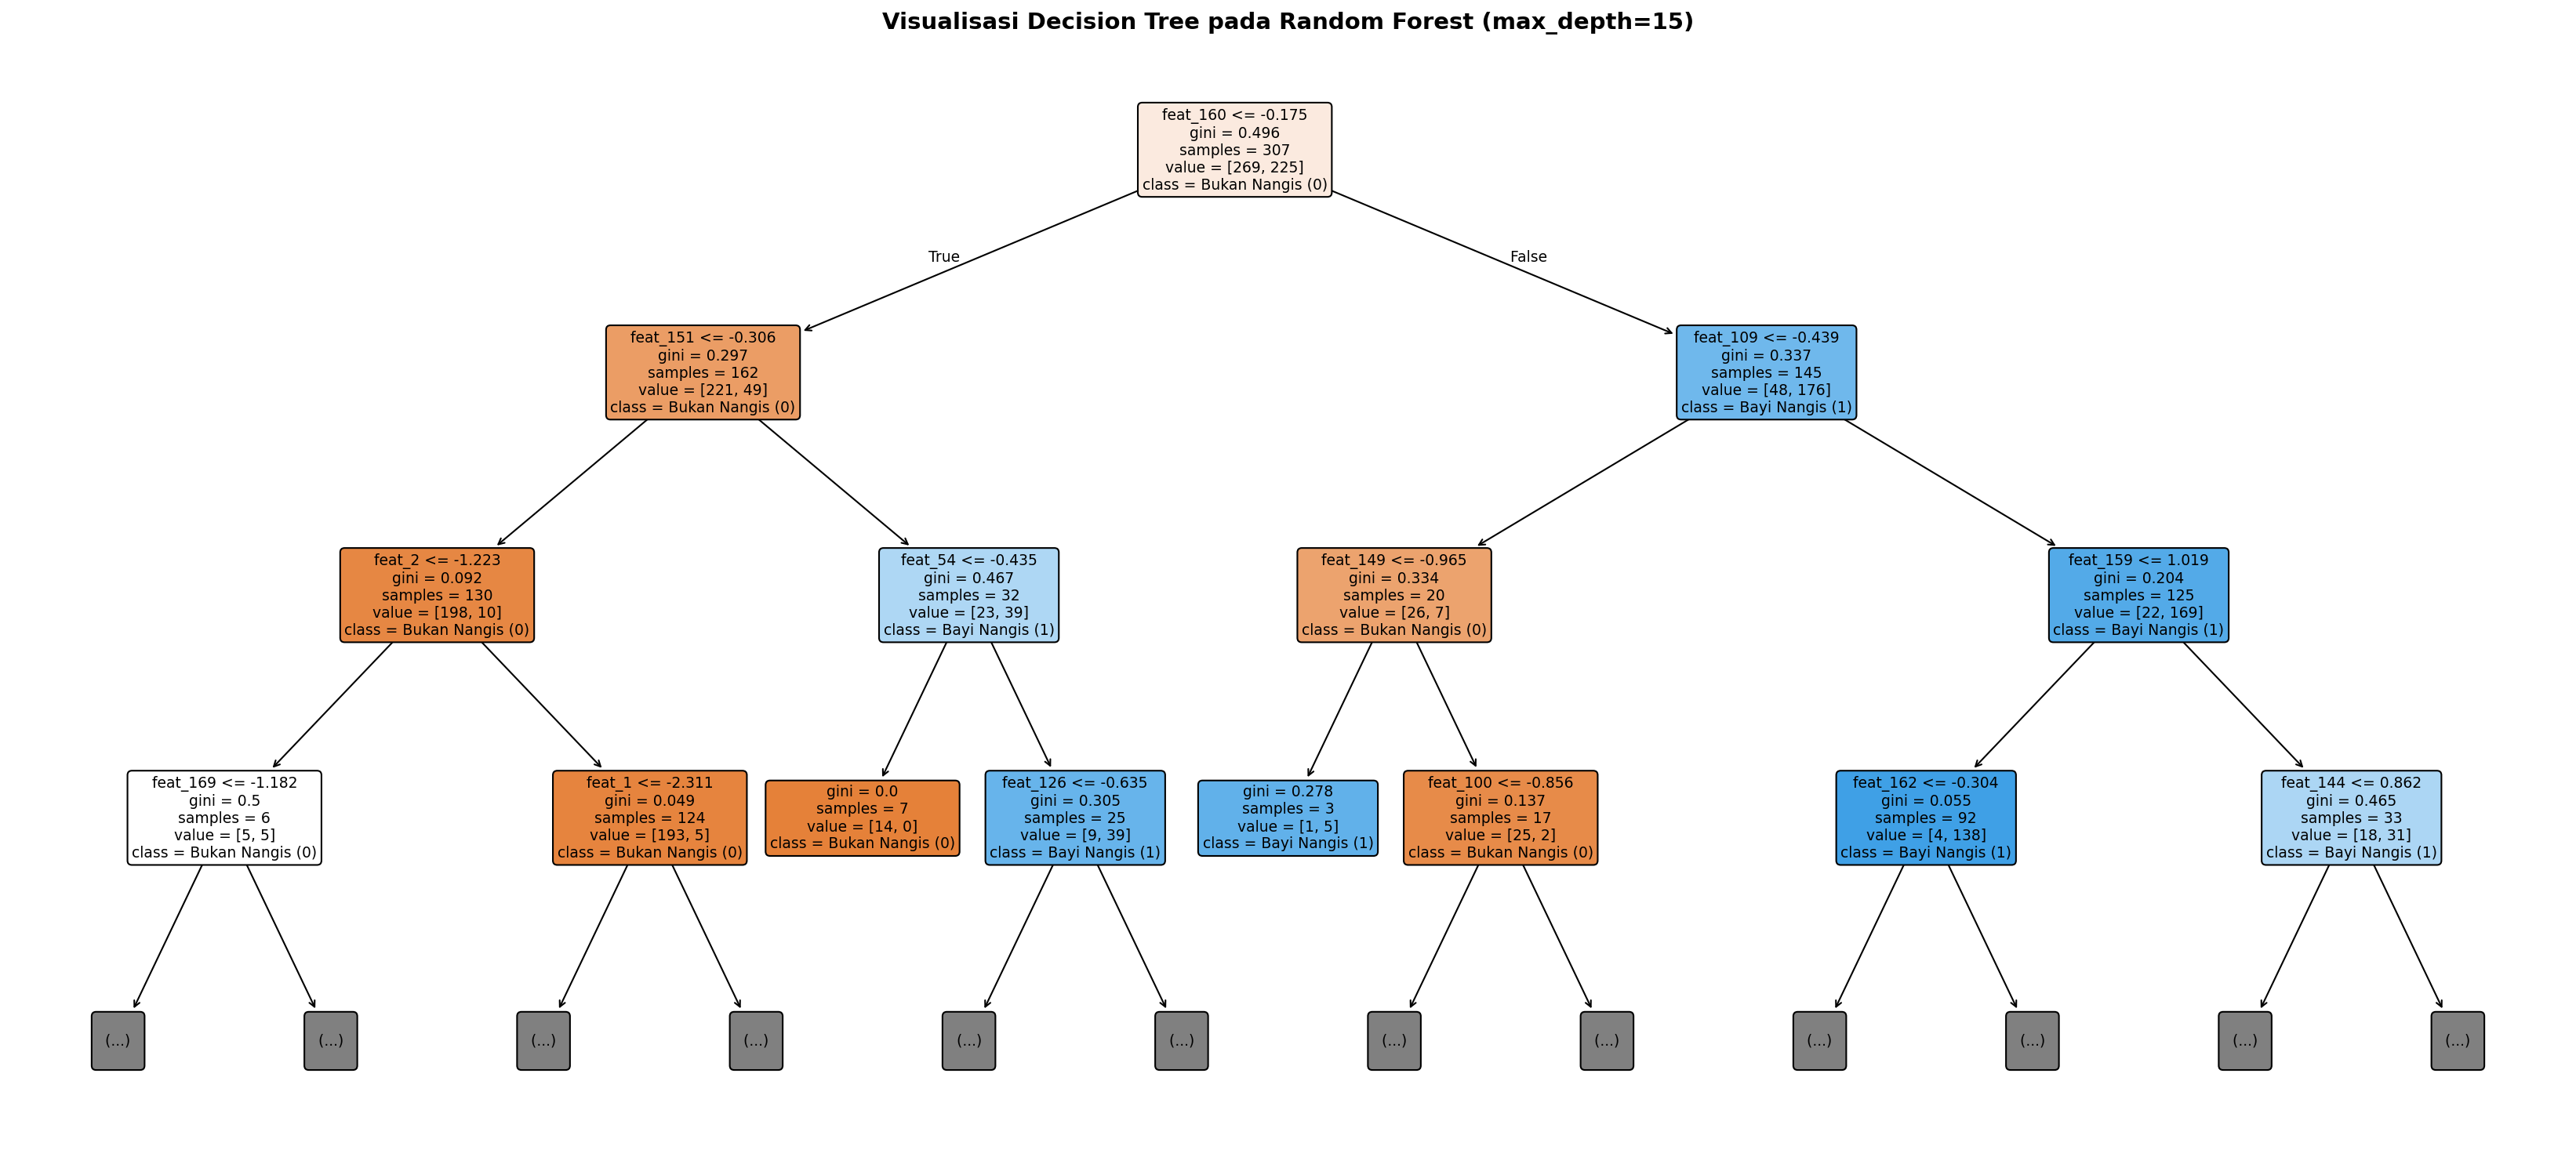

In [12]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Ambil pohon pertama dari model Random Forest terbaik
pohon_rf = model_rf.estimators_[0]

plt.figure(figsize=(22, 10), dpi=150)
plot_tree(
    pohon_rf,
    feature_names=feat_cols,
    class_names=["Bukan Nangis (0)", "Bayi Nangis (1)"],
    filled=True,
    rounded=True,
    max_depth=3,  # Menampilkan 3 level teratas agar teks terbaca jelas
    fontsize=9
)
plt.title(f"Visualisasi Decision Tree pada Random Forest (max_depth={grid_rf.best_params_['max_depth']})", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

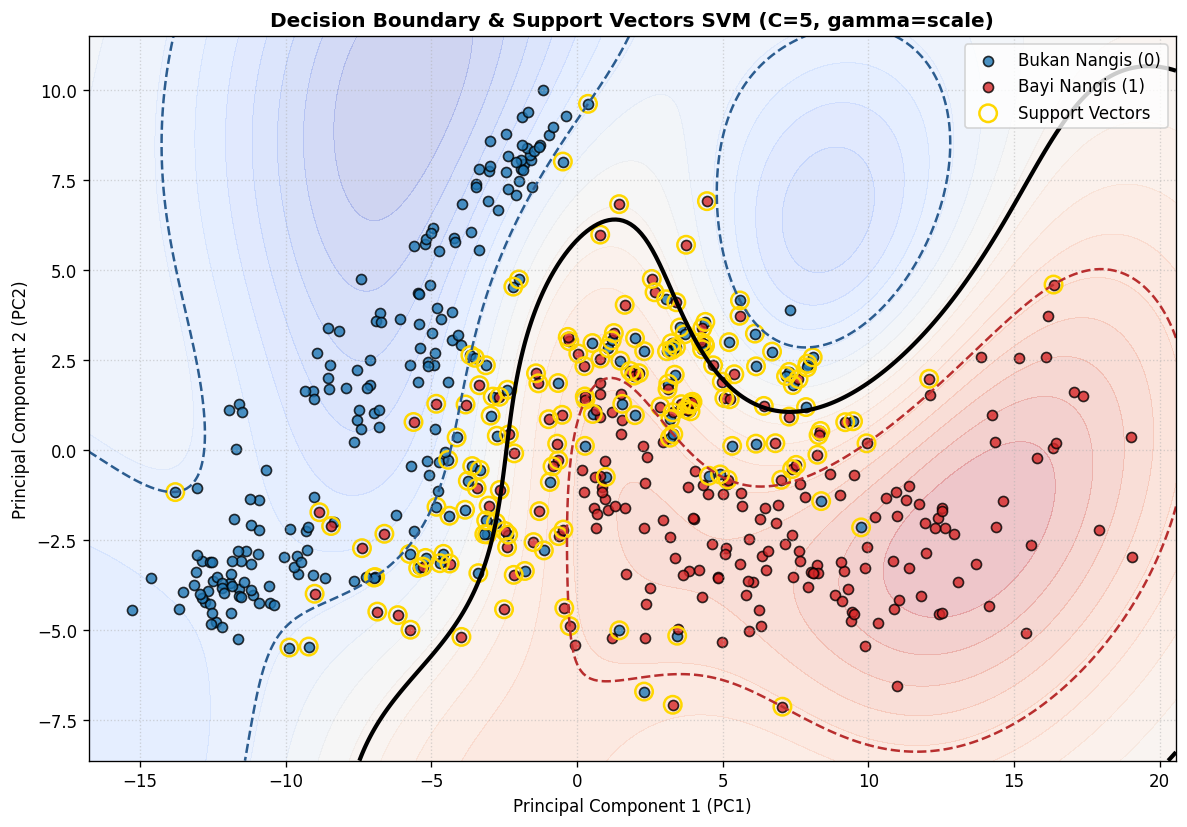

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.svm import SVC

# Proyeksikan 182 fitur ke 2D menggunakan PCA untuk visualisasi bidang pemisah
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

# Gunakan parameter terbaik hasil pemilihan dari GridSearchCV
best_c = grid_svm.best_params_["C"]
best_gamma = grid_svm.best_params_["gamma"]

svm_2d = SVC(kernel="rbf", C=best_c, gamma=best_gamma)
svm_2d.fit(X_train_pca, y_train)

x_min, x_max = X_train_pca[:, 0].min() - 1.5, X_train_pca[:, 0].max() + 1.5
y_min, y_max = X_train_pca[:, 1].min() - 1.5, X_train_pca[:, 1].max() + 1.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

Z = svm_2d.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(10, 7), dpi=120)
plt.contourf(xx, yy, Z, levels=np.linspace(Z.min(), Z.max(), 20), cmap="coolwarm", alpha=0.25)
plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["#2b5c8f", "black", "#b82e2e"], linestyles=["--", "-", "--"], linewidths=[1.5, 2.5, 1.5])

plt.scatter(X_train_pca[y_train == 0, 0], X_train_pca[y_train == 0, 1], c="#1f77b4", label="Bukan Nangis (0)", edgecolors="k", alpha=0.8)
plt.scatter(X_train_pca[y_train == 1, 0], X_train_pca[y_train == 1, 1], c="#d62728", label="Bayi Nangis (1)", edgecolors="k", alpha=0.8)
plt.scatter(svm_2d.support_vectors_[:, 0], svm_2d.support_vectors_[:, 1], s=110, facecolors="none", edgecolors="gold", linewidths=1.5, label="Support Vectors")

plt.title(f"Decision Boundary & Support Vectors SVM (C={best_c}, gamma={best_gamma})", fontsize=12, fontweight="bold")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.legend(loc="upper right")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

=== STRUKTUR POHON KE-1 (TREE 0) XGBOOST ===
0:[feat_170<-0.369630694] yes=1,no=2,missing=2
	1:[feat_4<-0.768569887] yes=3,no=4,missing=4
		3:[feat_3<-0.0522804298] yes=7,no=8,missing=8
			7:leaf=0.150050551
			8:leaf=-0.0168462005
		4:[feat_23<1.78143883] yes=9,no=10,missing=10
			9:leaf=-0.179717675
			10:leaf=-0.0394915007
	2:[feat_3<0.868028522] yes=5,no=6,missing=6
		5:[feat_118<2.47464108] yes=11,no=12,missing=12
			11:leaf=0.185736716
			12:leaf=-0.0742752254
		6:leaf=-0.165250316



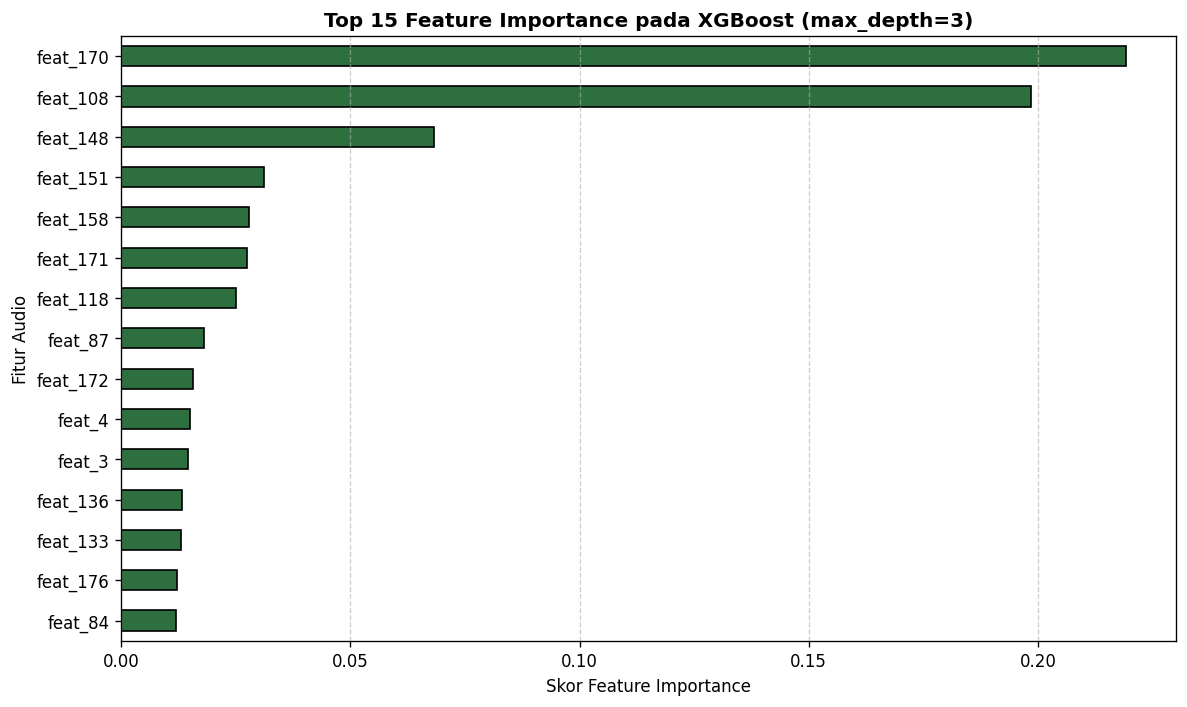

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Cetak struktur percabangan pohon pertama dari XGBoost
booster = model_xgb.get_booster()
booster.feature_names = list(feat_cols)
print("=== STRUKTUR POHON KE-1 (TREE 0) XGBOOST ===")
print(booster.get_dump(with_stats=False)[0])

# 2. Plot 15 fitur terpenting pembentuk pohon XGBoost
importances = pd.Series(model_xgb.feature_importances_, index=feat_cols).sort_values(ascending=True).tail(15)

plt.figure(figsize=(10, 6), dpi=120)
importances.plot(kind="barh", color="#2e6f40", edgecolor="black")
plt.title(f"Top 15 Feature Importance pada XGBoost (max_depth={grid_xgb.best_params_['max_depth']})", fontsize=12, fontweight="bold")
plt.xlabel("Skor Feature Importance")
plt.ylabel("Fitur Audio")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### TESTING
Tahap akhir pada *Modeling* adalah menguji performa ketiga model terbaik (`model_svm`, `model_rf`, dan `model_xgb`) terhadap 73 sampel data uji murni (`X_test_scaled`) menggunakan metrik *Accuracy*, *Precision*, *Recall*, *F1-Score*, serta visualisasi *Confusion Matrix* untuk menentukan satu model paling optimal yang akan diimplementasikan ke dalam aplikasi **Streamlit** dan sistem notifikasi **WhatsApp**.

=== TABEL PERBANDINGAN HASIL TESTING ===
        Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
    SVM (RBF)         80.82          65.62       87.50         75.00
      XGBoost         75.34          58.33       87.50         70.00
Random Forest         73.97          56.41       91.67         69.84

--- Classification Report: SVM (RBF) ---
                  precision    recall  f1-score   support

Bukan Nangis (0)       0.93      0.78      0.84        49
 Bayi Nangis (1)       0.66      0.88      0.75        24

        accuracy                           0.81        73
       macro avg       0.79      0.83      0.80        73
    weighted avg       0.84      0.81      0.81        73


--- Classification Report: Random Forest ---
                  precision    recall  f1-score   support

Bukan Nangis (0)       0.94      0.65      0.77        49
 Bayi Nangis (1)       0.56      0.92      0.70        24

        accuracy                           0.74        73
       mac

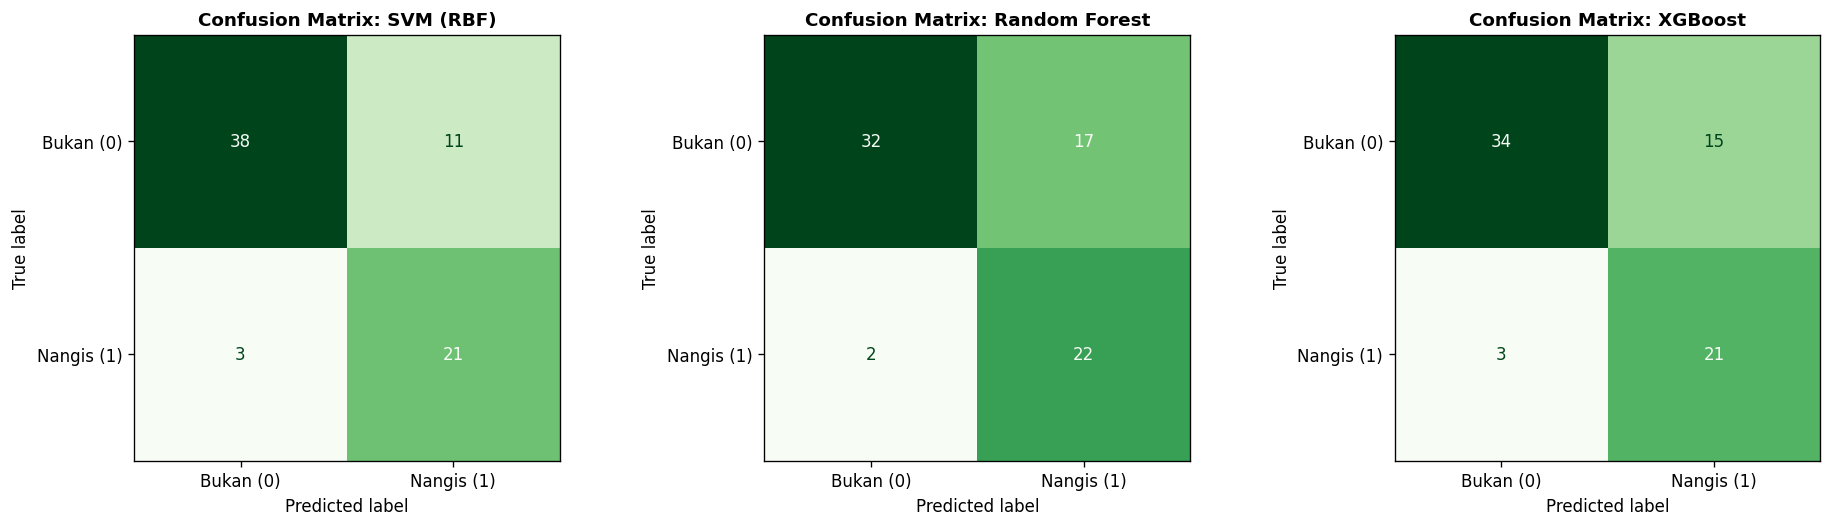

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# 1. Daftar model yang sudah ditraining di Cell 4
daftar_model = {
    "SVM (RBF)": model_svm,
    "Random Forest": model_rf,
    "XGBoost": model_xgb
}

hasil_evaluasi = []
prediksi_model = {}

# 2. Lakukan prediksi ke data testing (X_test_scaled)
for nama, model in daftar_model.items():
    y_pred = model.predict(X_test_scaled)
    prediksi_model[nama] = y_pred
    
    hasil_evaluasi.append({
        "Model": nama,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_test, y_pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_test, y_pred, zero_division=0) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, y_pred, zero_division=0) * 100, 2)
    })

# 3. Tampilkan Tabel Perbandingan Hasil Testing
df_evaluasi = pd.DataFrame(hasil_evaluasi).sort_values(by="F1-Score (%)", ascending=False).reset_index(drop=True)
print("=== TABEL PERBANDINGAN HASIL TESTING ===")
print(df_evaluasi.to_string(index=False))

# 4. Tampilkan Classification Report detail untuk masing-masing model
for nama, y_pred in prediksi_model.items():
    print(f"\n--- Classification Report: {nama} ---")
    print(classification_report(y_test, y_pred, target_names=["Bukan Nangis (0)", "Bayi Nangis (1)"]))

# 5. Visualisasi Confusion Matrix ketiga model secara berdampingan
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=120)

for ax, (nama, y_pred) in zip(axes, prediksi_model.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Bukan (0)", "Nangis (1)"])
    disp.plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(f"Confusion Matrix: {nama}", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

Hasil evaluasi ketiga model terhadap **73 sampel data uji murni** (terdiri dari 49 sampel `Bukan Nangis (0)` dan 24 sampel `Bayi Nangis (1)`) dirangkum pada tabel perbandingan berikut:

| Peringkat | Model Klasifikasi | Accuracy (%) | Precision (%) | Recall (%) | F1-Score (%) |
| :---: | :--- | :---: | :---: | :---: | :---: |
| **1** | **SVM (RBF)** | **80,82%** | **65,62%** | **87,50%** | **75,00%** |
| **2** | **XGBoost** | 75,34% | 58,33% | 87,50% | 70,00% |
| **3** | **Random Forest** | 73,97% | 56,41% | **91,67%** | 69,84% |

Adapun rincian jumlah prediksi benar dan salah pada masing-masing kelas berdasarkan *Classification Report* dan *Confusion Matrix* adalah sebagai berikut:

| Model Klasifikasi | True Negative (Bukan Nangis Terdeteksi Benar) | False Positive (Alarm Palsu / Dikira Nangis) | False Negative (Tangisan Terlewat / Gagal Deteksi) | True Positive (Bayi Nangis Terdeteksi Benar) |
| :--- | :---: | :---: | :---: | :---: |
| **SVM (RBF)** | **38 / 49** (77,6%) | **11 sampel** | **3 sampel** | **21 / 24** (87,5%) |
| **XGBoost** | 34 / 49 (69,4%) | 15 sampel | 3 sampel | 21 / 24 (87,5%) |
| **Random Forest** | 32 / 49 (65,3%) | 17 sampel | **2 sampel** | **22 / 24** (91,7%) |

**Analisis Hasil & Pemilihan Model Terbaik:**
* **Sensitivitas Deteksi (*Recall*) Tinggi pada Seluruh Model:** Ketiga algoritma menunjukkan kemampuan yang sangat kuat dalam mengenali suara tangisan bayi dengan capaian *Recall* di atas 87%. Artinya, dari 24 sampel audio bayi menangis pada data uji, SVM dan XGBoost berhasil mendeteksi 21 sampel, sedangkan Random Forest mendeteksi 22 sampel. Hal ini sangat krusial bagi sistem pemantauan bayi karena meminimalkan risiko tangisan bayi yang terlewat (*False Negative*).
* **Keseimbangan Terhadap Alarm Palsu (*Precision*):** Kelemahan utama pada Random Forest dan XGBoost terletak pada tingginya angka *False Positive* (masing-masing 17 dan 15 sampel suara lingkungan yang salah dikira tangisan bayi), sehingga nilai *Precision* keduanya turun ke angka 56,41% dan 58,33%. Sebaliknya, **SVM (RBF)** mampu menekan jumlah *False Positive* menjadi 11 sampel sekaligus mempertahankan *Precision* pada kelas `Bukan Nangis (0)` sebesar **93%** dan pada kelas `Bayi Nangis (1)` sebesar **65,62%**.
* **Keputusan Model Terpilih:** Berdasarkan perbandingan keseluruhan metrik, **SVM (RBF)** ditetapkan sebagai **model terbaik** karena unggul mutlak pada nilai **Accuracy (80,82%)**, **Precision (65,62%)**, dan **F1-Score (75,00%)**, dengan tingkat deteksi **Recall (87,50%)** yang tetap tinggi. Kemampuan kernel RBF dalam memisahkan 182 fitur akustik berdimensi tinggi terbukti paling stabil dalam mendeteksi tangisan bayi sekaligus menekan frekuensi pengiriman notifikasi palsu (*spam*), sehingga model **SVM (RBF)** inilah yang disimpan dan digunakan untuk tahap *deployment* ke dalam perangkat lunak **Streamlit** yang terintegrasi dengan notifikasi **WhatsApp**.

### Cetak Model Terbaik

In [18]:
import joblib

# Menyimpan model terbaik (SVM RBF) ke dalam file .pkl
MODEL_FILENAME = "model_svm_terbaik.pkl"
joblib.dump(model_svm, MODEL_FILENAME)

print(f"[*] Model terbaik (SVM RBF) berhasil disimpan ke: {MODEL_FILENAME}")
print("[*] Pastikan file 'model_svm_terbaik.pkl' dan 'scaler_audio.pkl'.")

[*] Model terbaik (SVM RBF) berhasil disimpan ke: model_svm_terbaik.pkl
[*] Pastikan file 'model_svm_terbaik.pkl' dan 'scaler_audio.pkl'.


### Alasan Pemilihan Algoritma Pemodelan

Pemilihan kandidat algoritma dalam penelitian ini didasarkan pada karakteristik struktural dataset hasil ekstraksi fitur (`X_train_scaled`), yang memiliki dimensi fitur tinggi (**182 fitur akustik kontinu**) dengan ukuran sampel pelatihan berskala menengah (**494 sampel**). Pada ruang berdimensi tinggi (*high-dimensional feature space*) dengan rasio fitur terhadap sampel yang cukup rapat, model klasifikasi rentan mengalami masalah kutukan dimensi (*curse of dimensionality*) serta *overfitting* apabila tidak memiliki mekanisme regularisasi yang kuat. Selain itu, karakteristik sinyal akustik tangisan bayi dan kebisingan lingkungan memiliki hubungan non-linear yang kompleks antar spektrum frekuensinya. 

Berdasarkan pertimbangan teknis tersebut, penelitian ini memilih dan membandingkan paradigma pemisahan hiperbidang (*kernel-based hyperplane*) dan ansambel pohon keputusan (*tree-based ensemble*) dengan rincian alasan sebagai berikut:

| Algoritma Klasifikasi | Paradigma Matematis | Alasan Pemilihan pada Kasus Klasifikasi 182 Fitur Audio |
| :--- | :--- | :--- |
| **1. Support Vector Machine (SVM - RBF Kernel)** | Pemisahan ruang berdimensi tinggi berbasis margin maksimum (*Maximum Margin Hyperplane*). | • **Tangguh pada Dimensi Tinggi:** SVM secara matematis sangat efektif menangani data dengan jumlah fitur yang banyak (182 kolom) meskipun jumlah sampel latih terbatas (494 baris), karena batas keputusan (*decision boundary*) hanya ditentukan oleh titik-titik kritis (*support vectors*).<br>• **Pemetaan Non-Linear via Kernel RBF:** Penggunaan *Radial Basis Function* (`rbf`) mampu memproyeksikan interaksi kompleks antara fitur *MFCC*, *Spectral Contrast*, dan *Centroid* ke ruang dimensi yang lebih tinggi sehingga kelas `bayi_nangis` dan `bukan_nangis` dapat dipisahkan secara tegas. |
| **2. Random Forest** | Ansambel paralel pohon keputusan berbasis *Bootstrap Aggregating* (*Bagging*). | • **Reduksi Variansi & Pencegahan *Overfitting*:** Sinyal audio lingkungan (*ESC-50*) mengandung banyak derau (*noise*) dan pencilan akustik. Dengan menggabungkan suara mayoritas (*majority voting*) dari ratusan pohon keputusan yang dilatih secara independen, Random Forest mampu menjaga stabilitas prediksi.<br>• **Seleksi Fitur Acak (`max_features='sqrt'`):** Pada setiap percabangan simpul, algoritma hanya mengevaluasi $\sqrt{182} \approx 13$ fitur secara acak, sehingga mencegah dominasi fitur tertentu yang saling berkorelasi tinggi (*multikolinearitas* antar koefisien MFCC). |
| **3. XGBoost (*Extreme Gradient Boosting*)** | Ansambel sekuensial pohon keputusan berbasis koreksi residu gradien (*Boosting*). | • **Fokus pada Sampel Sulit (*Hard Examples*):** Berbeda dengan *Bagging*, XGBoost membangun pohon keputusan secara bertahap di mana setiap pohon baru berfokus mengoreksi kesalahan klasifikasi (*residual error*) dari pohon sebelumnya. Hal ini sangat berguna untuk membedakan suara lingkungan berfrekuensi mirip tangisan bayi (seperti suara kucing atau tawa manusia).<br>• **Regularisasi Internal ($L_1$ & $L_2$):** Memiliki penalti kompleksitas pohon bawaan dan pengaturan kedalaman dangkal (`max_depth`) yang menahan model agar tidak menghafal *noise* pada data latih. |

## DEPLOYMENT

Hasil dari model, di deploy ke STREAMLIT

### LINK STREAMLIT

LINK : https://detectioncry-khetb4mndzhhcaggzwbglf.streamlit.app/

## Evaluation

Tahap **Evaluation** difokuskan untuk mengukur kemampuan generalisasi ketiga model terbaik terhadap **73 sampel data uji murni** (`X_test_scaled`), yang terdiri dari:
* **49 sampel** kelas *Bukan Nangis* (0)
* **24 sampel** kelas *Bayi Nangis* (1)

Evaluasi dilakukan secara kuantitatif menggunakan metrik:
* Accuracy
* Precision
* Recall
* F1-Score
* Analisis *Confusion Matrix*

Tujuan utama dari evaluasi ini adalah untuk mengidentifikasi sejauh mana model mampu meminimalkan kesalahan prediksi, khususnya kasus lolos deteksi (*False Negative*).


### Perbandingan Performa Model pada Data Uji

Berdasarkan hasil pengujian terhadap data uji murni tanpa augmentasi, rekapitulasi performa ketiga algoritma dirangkum dalam tabel berikut:

| Peringkat | Model Klasifikasi | Accuracy (%) | Precision (%) | Recall (%) | F1-Score (%) |
| :---: | :--- | :---: | :---: | :---: | :---: |
| **1** | **SVM (RBF)** | **80,82%** | **65,62%** | 87,50% | **75,00%** |
| 2 | XGBoost | 75,34% | 58,33% | 87,50% | 70,00% |
| 3 | Random Forest | 73,97% | 56,41% | **91,67%** | 69,84% |

Berdasarkan tabel di atas, **SVM dengan Kernel RBF** ditetapkan sebagai **model terbaik** karena:
* **Unggul pada mayoritas metrik utama**: Mencatat nilai tertinggi pada *Accuracy* (80,82%), *Precision* (65,62%), dan *F1-Score* (75,00%).
* **Sensitivitas tinggi**: Mempertahankan tingkat *Recall* sebesar **87,50%** (berhasil mendeteksi 21 dari 24 sampel tangisan bayi yang sebenarnya).


### Identifikasi Kelemahan Model & Analisis Kesalahan (*Error Analysis*)

Meskipun **SVM (RBF)** mencapai tingkat akurasi yang memuaskan (mendekati standar *benchmark* klasifikasi suara lingkungan ESC-50 sebesar **81,30%**), hasil evaluasi *Confusion Matrix* mengindikasikan beberapa kelemahan spesifik berikut:

* **Tingkat *Precision* Belum Optimal (65,62%)**: 
  Terdapat **11 sampel alarm palsu (*False Positive*)**. Suara lingkungan non-tangisan (seperti kucing mengeong, orang tertawa bernada tinggi, batuk, bersin, atau derau rumah tangga) keliru diprediksi sebagai tangisan bayi.
* **Karakteristik Akustik yang *Overlapping***: 
  Dipicu oleh kemiripan karakteristik spektral (*pitch* dan *frequency envelope*) antara lengkingan suara hewan peliharaan atau vokal manusia dewasa tertentu dengan frekuensi dasar tangisan bayi pada rentang **300 Hz – 3000 Hz**.
* **Kompromi Sensitivitas (*Recall* vs *Precision*)**: 
  Model sengaja dirancang lebih "waspada" terhadap risiko bayi menangis sehingga ** *Recall* mencapai 87,5%** (hanya meloloskan 3 sampel tangisan atau *False Negative*). Konsekuensinya, jumlah alarm palsu pada lingkungan bising meningkat.


### Arsitektur Teknis Sistem (*Hybrid Deployment*)

Untuk menjamin stabilitas performa komputasi pemrosesan audio sekaligus keamanan pengiriman pesan, sistem dibangun menggunakan **Arsitektur Hybrid**:

* **Antarmuka Pengguna & Mesin ML (*Streamlit Community Cloud*)**: 
  Berjalan di peladen *cloud* publik (`https://...streamlit.app`) untuk menangkap *streaming* mikrofon pengguna (*custom component* `mic_stream` / `st.audio_input`), mengekstraksi **182 fitur akustik** via pustaka `librosa`, dan menjalankan prediksi model SVM secara *real-time* setiap rentang waktu 10 detik.
* **Gateway Notifikasi WhatsApp (Panel Bot Node.js / Baileys)**: 
  Berjalan di dalam kontainer peladen privat pengguna (`https://abssbot.rbhost.my.id` melalui Port 1986). Ketika model SVM mendeteksi tangisan bayi (`prediksi == 1`), aplikasi Streamlit menembakkan permintaan HTTP POST (`requests.post`) ke *endpoint* `/kirim-notif` di panel bot, yang kemudian diteruskan secara instan ke nomor WhatsApp orang tua, panel bot di sewa melalui web autoresbot.com.
* **Fitur Keamanan Anti-Spam (*Cooldown* 30 Detik)**: 
  Sistem dilengkapi mekanisme penahanan otomatis selama **30 detik** pada setiap pengiriman notifikasi WhatsApp guna mencegah pemblokiran akun (*banning*) akibat lonjakan pesan beruntun (*spam*) di peladen WhatsApp.




### Pengujian Sistem dengan Berbagai Variasi Suara

Pengujian fungsionalitas aplikasi dan ketepatan respons sistem telah diuji menggunakan berbagai skenario jenis suara (input mikrofon langsung dan berkas audio uji):

| No | Jenis Skenario Suara Pengujian | Respon Klasifikasi Model (SVM) | Status & Tindakan Sistem WhatsApp | Keterangan / Evaluasi Lapangan |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **Suara Tangisan Bayi Asli** | Bayi Nangis (Label 1, *Confidence* > 75%) | **Terkirim ✓**<br>(Pesan darurat langsung masuk ke nomor WA tujuan). | Sistem bereaksi cepat dan akurat dalam mendeteksi pola lengkingan suara bayi. |
| **2** | **Suara Lingkungan Senyap / Hening** | Bukan Nangis (Label 0) | **Diabaikan**<br>(Tidak ada pesan terkirim). | Filter energi minimum (`SILENCE_RMS`) berhasil mencegah analisis pada area tanpa suara. |
| **3** | **Suara Kucing Mengeong / Tawa Tinggi** | Bukan Nangis atau sesekali *False Positive* (Bayi Nangis) | **Terkirim hanya jika** *confidence* melampaui ambang batas model. | Membuktikan adanya tantangan *overlapping* frekuensi suara tinggi seperti dianalisis pada bab Evaluasi. |
| **4** | **Uji Tombol Manual (📲 Test WA)** | Simulasi Test Koneksi (*Confidence* 99,99%) | **Terkirim ✓**<br>(Pesan uji coba instan dengan hitung mundur *cooldown* 30 detik). | Memastikan jalur komunikasi HTTP POST antara Streamlit dan Bot Panel berjalan lancar tanpa hambatan. |

